# DSC212 Assignment: Karate Club
Amarnath K (IMS25021)

October 2026

---

## Introduction
This is my submission for the 2026 DSC212 (Mathematical Foundations to Data Science) course assignment at IISER TVM.

Given is a graph of a karate club, the nodes being people, and edges being drawn between them if they interact often. In this group, a split occurs, and asked of us is to find who belongs to what community/group. This follows from a popular dataset recorded by Zachary, W.

The following solution implements modularity and recursive spectral bipartition to find multiple communities within a given dataset.

All code must be run linearly from the first block to the last for it to be error-free.

## Setting up
Let's start with importing the required dataset and tools that will be used throughout this. As in the assignment sheet, I use `NetworkX`. Additionally I also use `numpy` for matrix algebra and `matplotlib` for visualisation.

The graph itself is available within `NetworkX`, which is what I am using here.

Note that the `numpy.set_printoptions()` command is only there so that whenever I print a matrix it doesnt have large decimal tails (ex. 1.23234324 becomes 1.23).

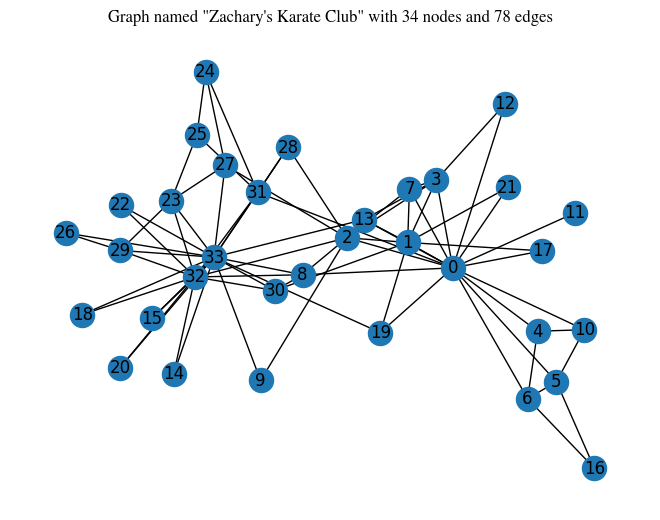

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'STIXGeneral' # i find the default font looks ugly

np.set_printoptions(precision=2, suppress=True)

G = nx.karate_club_graph()
G_cpy = G.copy() # graph to cut edges from

nx.draw(G, with_labels=True) # shows the graph
plt.title(G)
plt.show()

## Calculating the required matrices
For our community detection algorithm, we need some way to judge what community a node will be part of. Here, as instructed, I am using modularity as the distinguishing parameter. The modularity matrix $\mathbf B$ is defined as

$$ \mathbf B = \mathbf A - \frac{1}{2m} \mathbf k \mathbf k^T$$

where $\mathbf A$ is the adjacency matrix of `G`, $m$ is the number of edges, and $\mathbf k = \left< k_i\right>^n$ is a vector of the degrees of all nodes.

Implementing this globally in the code (since this calculation need not be done again), we have,

In [ ]:
m = G.number_of_edges()

A_global = nx.adjacency_matrix(G, weight=None).toarray() # i have no use for weights
k_global = np.array([deg for node, deg in G.degree])
B_global = A_global - np.outer(k_global, k_global)/(2*m) # k k T is an outer product

print(B_global)

[[-1.64  0.08 -0.03 ...  0.38 -1.23 -1.74]
 [ 0.08 -0.52  0.42 ... -0.35 -0.69 -0.98]
 [-0.03  0.42 -0.64 ... -0.38  0.23 -1.09]
 ...
 [ 0.38 -0.35 -0.38 ... -0.23  0.54  0.35]
 [-1.23 -0.69  0.23 ...  0.54 -0.92 -0.31]
 [-1.74 -0.98 -1.09 ...  0.35 -0.31 -1.85]]


Next, I am defining a queue to store the lists of nodes that need checked for the presence of communities. Since initially we have no known communities, I give it the graph itself as input.

Similarly, for the final set of communities, I create another list called `communities`. It will be empty. I also define a dictionary called `iteration`. It has the format `<iteration id>: <split communities>`. If there is no split it will return the same community as input. For each split that is made, I will increment a variable `split`. The 0th split is the prediction for Zachary's observations (Mr. Hi and Administrator groups).

Additionally, I have `Q` and lists for each of the node metrics.

In [ ]:
queue = [[node for node, deg in G.degree],]
communities = []
iteration = {}
iter = 0
split = -1

degree_centralities = []
betweenness_centralities = []
closeness_centralities = []
clustering_coefficients = []

Q = 0

print(queue)

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]


## The algorithm: Recursive Spectral Bipartition
In the assignment, it was given that the steps to be followed are:
1. Start with the full node set $V$.
2. Compute the modularity matrix $\mathbf B$ for the induced subgraph.
3. Find the leading eigenpair $(\lambda_1$, $\mathbf u_1)$.
4. If $\lambda_1 \leq 0$: stop; the group is indivisible.
5. Else: split nodes into $C^+$ and $C^-$ by the sign of $\mathbf u_1$.

6. Recurse on $C^+$ and $C^-$ separately.

To follow these steps, I have devised a `while` loop that runs as long as `queue` is not empty. Every time, it takes the first element of `queue` and applies spectral bipartition on it, using the above rules. Using `numpy`, I calculate the eigenvalues, take the largest eigenpair and then divide the graph into communities, and add them into the queue. If there are degenerate communites (nodeless communities) or the largest eigenvalue is not positive, it throws the community from `queue`. Thar particular community is no longer divisible.

Iterating this recursively, we obtain a set of communities, which is saved in the variable `communities`.

I will explain the below code in the text box that follows it.


In [ ]:
def update_vars():
  global communities, queue, iteration, iter
  popped = queue.pop(0)
  communities.append(popped)

while queue:
  iter += 1
  B = B_global[np.ix_(queue[0], queue[0])]

  eigval, eigvec = np.linalg.eigh(B)
  largest_eigval  = eigval[-1]    # largest is last with eigh
  largest_eigvec  = eigvec[:, -1].real

  if largest_eigval <= 0:
    update_vars()
    continue

  community = queue[0]

  s = np.where(largest_eigvec > 0, 1, -1)

  delQ = np.dot(s, np.matmul(B, s))/(4*m)
  Q += delQ
  print(f"At iteration \033[32m{iter:<4}\033[0m\
   delQ \033[32m{delQ:<7.3}\033[0m Q \033[32m{Q:<7.3}\033[0m")

  if delQ <= 0:
    update_vars()
    continue

  group1 = [community[i] for i in range(len(community)) if s[i] ==  1]
  group2 = [community[i] for i in range(len(community)) if s[i] == -1]

  if not group1 or not group2:   # degenerate split
    update_vars()
    continue

  iteration[iter] = (group1, group2)


  split += 1
  edges_to_remove = list(nx.edge_boundary(G_cpy, group1, group2))
  G_cpy.remove_edges_from(edges_to_remove)
  degree_centralities.append(nx.degree_centrality(G_cpy))
  betweenness_centralities.append(nx.betweenness_centrality(G_cpy))
  closeness_centralities.append(nx.closeness_centrality(G_cpy))
  clustering_coefficients.append(nx.clustering(G_cpy))

  queue.append(group1)
  queue.append(group2)

  queue.pop(0)

At iteration 1      delQ 0.371   Q 0.371  
At iteration 2      delQ 0.111   Q 0.483  
At iteration 3      delQ 0.111   Q 0.594  
At iteration 4      delQ 0.0695  Q 0.663  
At iteration 5      delQ 0.0338  Q 0.697  
At iteration 6      delQ 0.0246  Q 0.722  
At iteration 7      delQ 0.0774  Q 0.799  
At iteration 9      delQ 0.0332  Q 0.832  


### The `update_vars()` function
Every time we iterate through a community, when we reach a stop condition, we need to remove that particular community from `queue` and add it to final list `communities`.
> Removed: Additionally, to keep track of iterations, I also add the iteration number and the split formed. This is done using the `update_vars()` function as follows.
Cause of removal: It interfered with the visualisation code down this page, and I did not find much use for it to track non-split iterations anyways.

```py
def update_vars():
  global communities, queue, iteration, iter
  popped = queue.pop(0)
  communities.append(popped)
```

### The `while` loop
The while loop runs until `queue` is emptied, i.e., there are no more communities to check.

Every iteration, it takes the first community in `queue`, let's say $C$, and takes the modularity matrix $\mathbf B^{(C)}$ from the blocks of $\mathbf B$ corresponding to the involved nodes using `np.ix_()`.

>*`X[np.ix_(rows, cols)]` returns a matrix consisting of the rows and columns of `X`. Consider reading [Appendix A](https://colab.research.google.com/drive/12XnHmLt-ylLhQz4xCH_WCcic5ixp2UJ6?authuser=2#scrollTo=8jUO1XvOipj_&line=3&uniqifier=1) for info on `np.ix_()`.*

Following this is
```py
  eigval, eigvec = np.linalg.eigh(B)
  largest_eigval  = eigval[-1]    # largest is last with eigh
  largest_eigvec  = eigvec[:, -1].real

  if largest_eigval <= 0:
    update_vars()
    continue
```
Since $\mathbf B$ is a symmetric matrix, `np.linalg.eigh()` will be sufficient to obtain the largest eigenvalue and corresponding eigenvector. One advantage of `eigh()` as opposed to `eig()` is that in the list of eigenvalues it returns, the largest one will always be at index `-1`. This is what I have made use of here. **If this value is less than or equal to 0 we have reached our first stopping condition**, as this means that the given community is not further divisible. Update variables and then skip to the next iteration.

Now, we need a way to get the matrix $\mathbf s$ such that we may identify which node belongs to what community. As per the assignment, for each node, if the eigenvector component is positive, we let it be part of community $C^+$, else $C^-$.
```py
  s = np.where(largest_eigvec > 0, 1, -1)
```
`np.where()` is a conditional selection function, which assigns, for all components of `s`, the value of `1` if its corresponding component in `largest_eigenvec` is greater than `0`, else the value `-1`.

We assign each node to $C^+$ and $C^-$ (here `group1` and `group2`), and we update our global variables and skip to the next community in `queue` (**the second stopping condition**) using the following code.
```py
  group1 = [community[i] for i in range(len(community)) if s[i] ==  1]
  group2 = [community[i] for i in range(len(community)) if s[i] == -1]
  iteration[iter] = (group1, group2)

  if not group1 or not group2:   # A
    update_vars()
    continue

  queue.append(group1)
  queue.append(group2)

  queue.pop(0)
```
Note the `if` statement here exists only so that our algorithm does not push empty lists (`[]`) into `queue`, which would break the code.

This completes the community separation process. Now we move on to data collection and visualisation of all splits made.

Additionally, all the node metrics are added and the value of split is incremented by `1` if a split is detected.

## Node metrics
I have also, as per the assignment's instructions, added, whenever a split occurs, a calculation of a few node metrics for visualisation. Calculated metrics are,

### Degree centrality
The degree centrality measures the fraction of nodes that are connected to the given node in a network, and mathematically it is defined as
\\[ C_D(i) = \frac{k_i}{n-1} \\]
where $n$ is the number of nodes.

### Betweenness centrality
Answers the question: how often does a node lie in the shortest path between two nodes. Measures if a node could potentially act as a bridge. Defined as
\\[ C_B(i) = \sum_{s\neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}} \\]
where $\sigma_{st}$ is the number of shortest paths between $s$ and $t$.

### Closeness centrality
Answers the question: how reachable is a node from another node in the graph. Defined as
\\[ C_C (i) = \frac{n-1}{\sum_{j\neq i} d(i, j)}\\]
where $d(i, j)$ is the shortest path distance between $i$ and $j$.

### Clustering coefficient
Answers teh question: how connected are the nodes a given node is connected to. High clustering coefficient would mean that a community could be present somewhere in the graph, and the given node might be part of it. Defined as

\\[ C(i) = \frac{2T(i)}{k_i(k_i-1)}\\]
where $T(i)$ is the number of triangles (3-node closed loops) passing through a specific node $i$.

### Calculating node metrics for a split
Every iteration where a split occurs, on the copy of the graph `G_cpy`, I find the edges that cross the split, and then remove them using the following code.
```py
  edges_to_remove = list(nx.edge_boundary(G_cpy, group1, group2))
  G_cpy.remove_edges_from(edges_to_remove)
```

After the edges are removed, on the new subgraph of `G`, i.e., `G_cpy`, I calculate the metrics using the below block of functions and store them in their respective lists, indexed by split.
```py
  degree_centralities.append(nx.degree_centrality(G_cpy))
  betweenness_centralities.append(nx.betweenness_centrality(G_cpy))
  closeness_centralities.append(nx.closeness_centrality(G_cpy))
  clustering_coefficients.append(nx.clustering(G_cpy))
```

In [ ]:
print("\033[32mQueue (should be empty):\033[0m", queue)

for i in range(len(communities)):
  print(f"\033[32mCommunity {i+1:<5}:\033[0m {str(communities[i])}")

Queue (should be empty): []
Community 1    : [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2    : [24, 25, 27, 28, 31]
Community 3    : [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4    : [11]
Community 5    : [4, 5, 6, 10, 16]


Above we have the final communities that were found through our method. To visualise this, we will use NetworkX and Matplotlib.

## Visualisation of metrics
First, we look at all the splits in the network that our algorithm has detected. The following code outputs those.

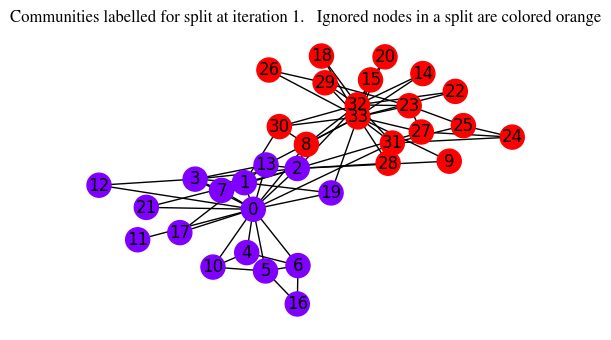

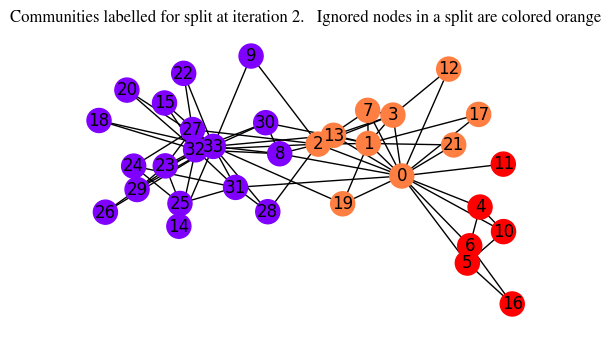

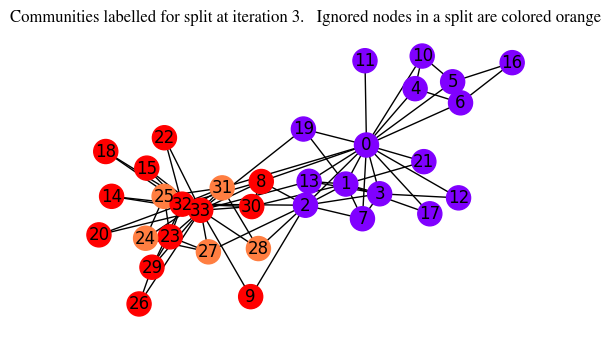

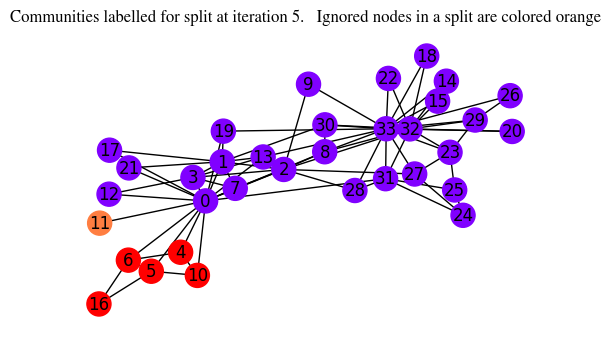

In [ ]:

for i in iteration:
  plt.figure(figsize=(5,3))
  colors = []
  for j in range(0, len(G.degree)):
    found = False
    for k in range(len(iteration[i])):
      if j in iteration[i][k]:
        colors.append(k)
        found = True
    if found == False:
      colors.append(-5)
  nx.draw(G, with_labels=True, node_color=colors, cmap=plt.cm.rainbow)
  plt.title(f"Communities labelled for split at iteration {i}. \
  Ignored nodes in a split are colored orange")
  plt.show()

### The final picture: all communities
 We look here at the final graph, with all its communities labelled. We see that there are four communities and a lone node.

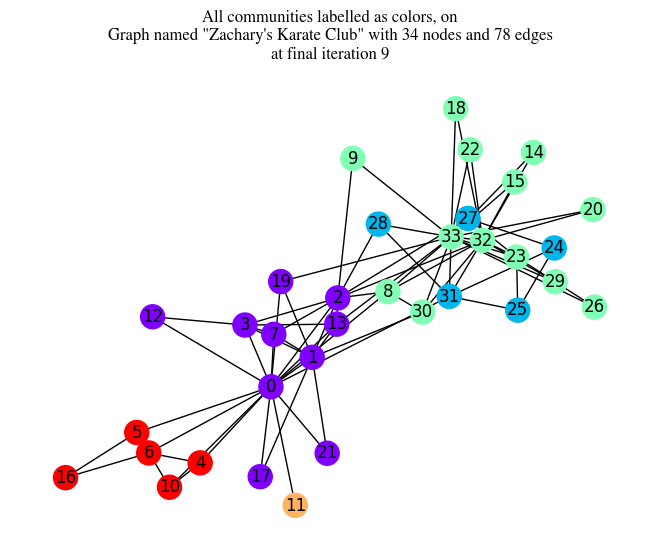

In [ ]:
colors = []
for i in range(0, len(G.degree)):
  for j in range(len(communities)):
    if i in communities[j]:
      colors.append(j)

nx.draw(G, with_labels=True, node_color=colors, cmap=plt.cm.rainbow)
plt.title(f"All communities labelled as colors, \
on\n{G}\nat final iteration {iter}")
plt.show()

Next, we plot the node metrics. I decided to visualise this in two ways: one as a simple plot of value against iteration, where each colour line represents a node. Since this is kind of useless as a visualisation, I decided that it would be better if the node metrics are plotted on the nodes themselves, as a gradient of color. What follows are those graphs.

> *Yes, I know how horribly clunky this particular part of the code looks, and I am sorry for that.* :(

### Node metrics visualised as a simple plot

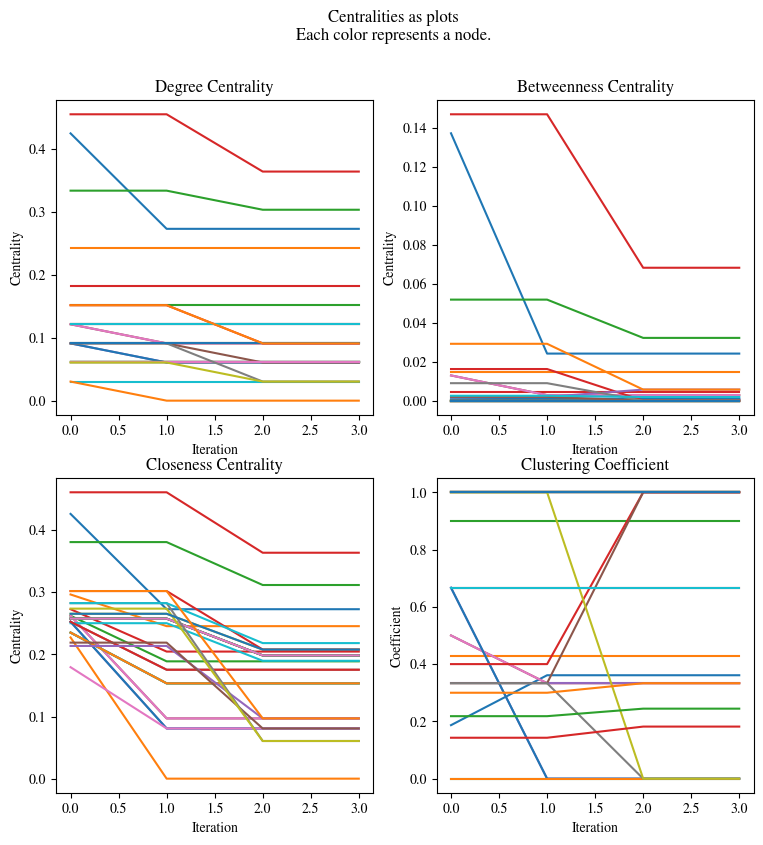

In [ ]:
dc_nodes = list(zip(*(d.values() for d in degree_centralities)))
bc_nodes = list(zip(*(d.values() for d in betweenness_centralities)))
cc_nodes = list(zip(*(d.values() for d in closeness_centralities)))
cluster_nodes = list(zip(*(d.values() for d in clustering_coefficients)))

fig, axs = plt.subplots(2, 2, figsize=(9, 9))
for i in range(G.number_of_nodes()):
  splits = [x for x in range(split+1)]
  axs[0, 0].plot(splits, list(dc_nodes[i]))
  axs[0, 0].set_title('Degree Centrality')
  axs[0, 0].set_xlabel('Iteration')
  axs[0, 0].set_ylabel('Centrality')

  axs[0, 1].plot(splits, bc_nodes[i])
  axs[0, 1].set_title('Betweenness Centrality')
  axs[0, 1].set_xlabel('Iteration')
  axs[0, 1].set_ylabel('Centrality')

  axs[1, 0].plot(splits, cc_nodes[i])
  axs[1, 0].set_title('Closeness Centrality')
  axs[1, 0].set_xlabel('Iteration')
  axs[1, 0].set_ylabel('Centrality')

  axs[1, 1].plot(splits, cluster_nodes[i])
  axs[1, 1].set_title('Clustering Coefficient')
  axs[1, 1].set_xlabel('Iteration')
  axs[1, 1].set_ylabel('Coefficient')
fig.suptitle("Centralities as plots\nEach color represents a node.")
fig.show()




### Node metrics visualised on the network
Following are the node metrics visualised as colours on the nodes of the network. I have plotted, for each node,
- Degree centrality,
- Betweenness centrality,
- Closeness centrality, and,
- Clustering coefficient

Darker colors mean higher values.


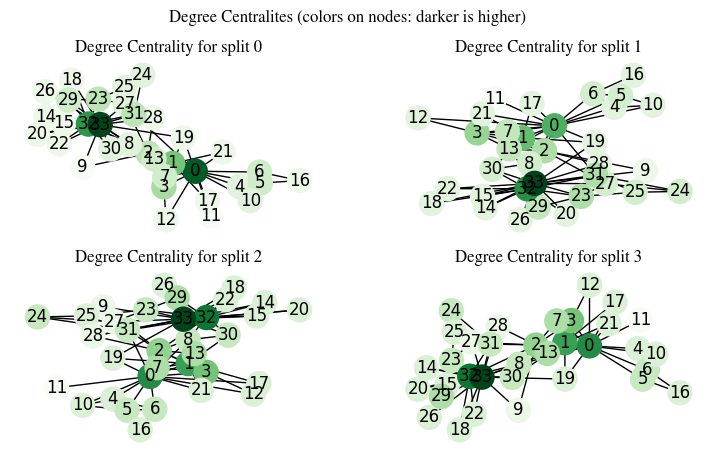

In [ ]:
fig, axs = plt.subplots((split+1)//2, 2, figsize=(9, 5))

fig.suptitle(f"Degree Centralites (colors on nodes: darker is higher)")

for i in range(split+1):
  ax_curr = axs[i//2, i%2]
  nx.draw(G, ax = ax_curr,  with_labels=True, node_color=degree_centralities[i].values()\
          , cmap = plt.cm.Greens)
  ax_curr.set_title(f"Degree Centrality for split {i}")
fig.show()

You can see that the nodes `0` and `33` have a very high degree centrality compared to the rest of the network nodes. These two are more likely to interact with any given node than other nodes in the network.

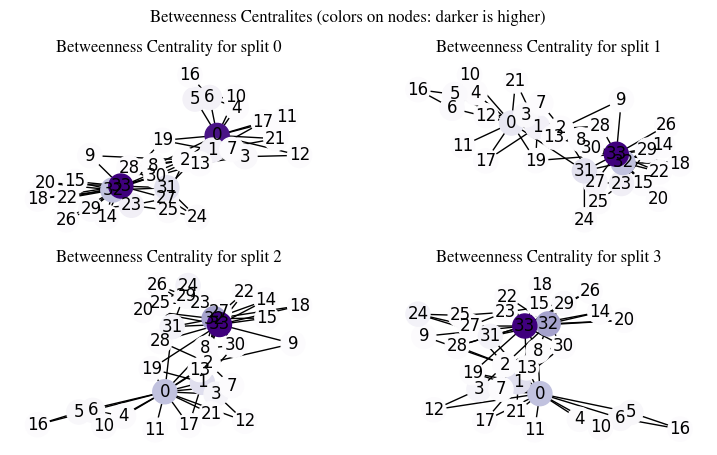

In [ ]:
fig, axs = plt.subplots((split+1)//2, 2, figsize=(9, 5))

fig.suptitle(f"Betweenness Centralites (colors on nodes: darker is higher)")

for i in range(split+1):
  ax_curr = axs[i//2, i%2]
  nx.draw(G, ax = ax_curr,  with_labels=True, node_color \
          =betweenness_centralities[i].values() \
          , cmap = plt.cm.Purples)
  ax_curr.set_title(f"Betweenness Centrality for split {i}")
fig.show()

Here `0` and `33` had high betweenness centrality in the first split, but 0 loses its high betweenness centrality after the first split. This could mean that `0` was a **bridge node**, i.e., it was one of the few nodes connecting the now split communities. When it chose one community, it lost a lot of its connections.

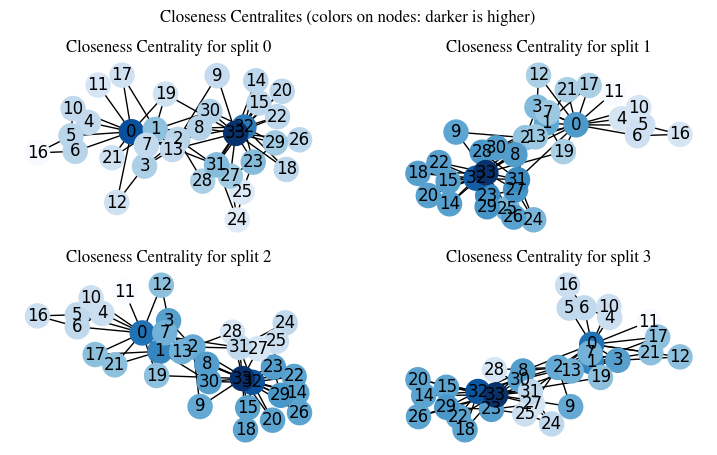

In [ ]:
fig, axs = plt.subplots((split+1)//2, 2, figsize=(9, 5))

fig.suptitle(f"Closeness Centralites (colors on nodes: darker is higher)")

for i in range(split+1):
  ax_curr = axs[i//2, i%2]
  nx.draw(G, ax = ax_curr,  with_labels=True, node_color \
          =closeness_centralities[i].values() \
          , cmap = plt.cm.Blues)
  ax_curr.set_title(f"Closeness Centrality for split {i}")
fig.show()

A high closeness centrality could be interpreted with a simple example of a rumor I believe. If a node recieves a rumor, it is highly likely that most of the group others will hear of it quicker than if any other node recieved it, if it has a high closeness centrality. Here again, 0 and 33 tend to be those spreaders of rumors!

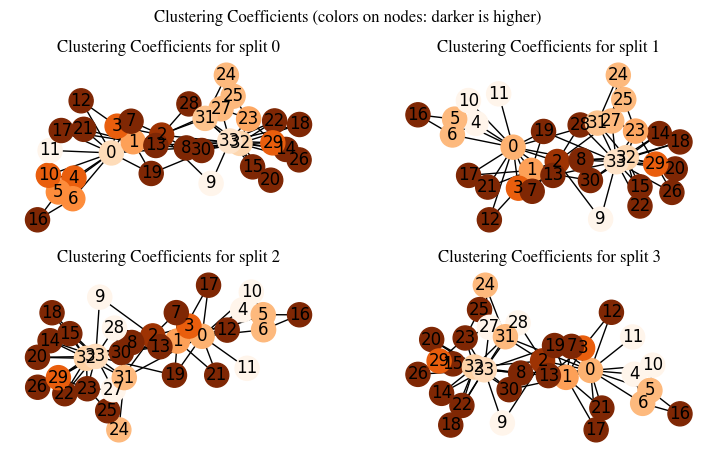

In [ ]:
fig, axs = plt.subplots((split+1)//2, 2, figsize=(9, 5))

fig.suptitle(f"Clustering Coefficients (colors on nodes: darker is higher)")

for i in range(split+1):
  ax_curr = axs[i//2, i%2]
  nx.draw(G, ax = ax_curr,  with_labels=True, node_color\
          =clustering_coefficients[i].values()\
          , cmap = plt.cm.Oranges)
  ax_curr.set_title(f"Clustering Coefficients for split {i}")
fig.show()

I still have not got the complete grasp of this, but I believe a higher clustering coeffcient for a group of nodes means they are more likely to form a community? Perhaps.

## References
1. Newman (2006), "Modularity and community structure in
networks". *PNAS* 103(23):8577-8582.
2. Zachary, W. W. (1977). "An Information Flow Model for Conflict and Fission in Small Groups". *Journal of Anthropological Research*. 33 (4): 452-473. arXiv:1707.03587. doi:10.1086/jar.33.4.3629752. JSTOR 3629752. S2CID 197843028.

---

## Appendices, and Responsible AI Use

### Appendix A: `np.ix_()`
The `np.ix_()` function is a very useful matrix function that allows you to make a new matrix from values in anohter matrix, taking only the given rows and columns. For example, if I had a matrix

$$ \mathbf X =
\begin{bmatrix} a & b & c & d \\
e & f & g & h \\
i & j & k & l \\
m & n & o & p \end{bmatrix}$$

If I did `np.ix_([1, 2, 3], [1, 3])`, it would give me a new matrix

$$ \mathbf Y = \begin{bmatrix}
f & h \\ j & l \\ n & p
 \end{bmatrix} $$

### Responsible AI Use
I can proudly say that most of this assignment was wrriten by me personally. I have however, used AI, and in doing so I have tried to use it in places that will not hinder my learning. I have used it to debug visual errors in matplotlib plots and also for general info on some concept. Once I had an error where I did not use the modularity matrix that I calculated globally and instead calculated every single iteration of the main `while` loop. This mistake cost me hours and I eventually got frustrated enough that I asked claude to tell me where I went wrong.

Other than this, I have used AI to find ways to simplify my logic, such as finding the `np.ix_()` function, as otherwise I would have to write the logic to do that myself. However I have not let AI write any code for me other than the cases mentioned above.

## PS :3
You may remember receiving an Email from one of my batchmates about how he got 12 communities. I am his roommate, and I can agree with him on the fact that this was probably the most fun assignment so far in our time here! It was very fun to debug ALL the massive issues with our code (even if it gave me headaches for a weekend)!